# Hwang et al. 2022 — PDAC
## 03 · Developmental signatures & Gate 2
Score Gast / pSom / Crest with the union control pool, render raw signature UMAPs (house style), and settle **Gate 2** from the module geography: is there a Gast/pSom co-expression hub diverging into two arms (branching), or a single organized axis with a terminal Crest gradient (non-branching)?

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc
import scipy.sparse as sp
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 0
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars'); pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
print('loaded manifold.h5ad:', adata.shape)
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present (control pool = {g_ref.size} union genes)')

loaded manifold.h5ad: (64006, 19444)
Gast: 77/81 genes present (control pool = 228 union genes)
pSom: 92/98 genes present (control pool = 228 union genes)
Crest: 101/104 genes present (control pool = 228 union genes)


**Gate 2 — module geography.** Three quantitative reads decide branching vs non-branching:
1. **Co-expression hub test** — enrichment of Gast-high & pSom-high co-occurrence vs independence (>1 = a co-expression hub -> candidate bifurcation; <1 = the two poles are mutually exclusive -> a single cross-repression axis).
2. **Smoothed spatial correlations** — Gast vs pSom, and Crest vs each.
3. **Terminal Crest** — is the Crest-high decile at late pseudotime?

In [5]:
gz = (adata.obs['Gast_sm']-adata.obs['Gast_sm'].mean())/adata.obs['Gast_sm'].std()
pz = (adata.obs['pSom_sm']-adata.obs['pSom_sm'].mean())/adata.obs['pSom_sm'].std()
joint = ((gz>0.5)&(pz>0.5)).mean(); exp = (gz>0.5).mean()*(pz>0.5).mean()
print(f'Gast&pSom co-high enrichment = {joint/exp:.2f}  (>1 = co-expression hub; <1 = mutually exclusive poles)')
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.3f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
for m,lab in [('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation'),('Crest_sm','Neural-crest')]:
    hi = adata.obs[m] >= adata.obs[m].quantile(0.9)
    print(f'{lab}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
# Crest-arm flag: which developmental pole does Crest co-localize with?
rg = abs(np.corrcoef(adata.obs.Crest_sm, adata.obs.Gast_sm)[0,1])
rp = abs(np.corrcoef(adata.obs.Crest_sm, adata.obs.pSom_sm)[0,1])
print('Crest-arm: Crest anti-correlates more strongly with', 'pSom (expected terminal readout on somitogenesis side)' if rp>rg else 'Gast (FLAG: inversion)')
print('GATE 2 = GO (non-branching): single organized cross-repression axis (Gast<->pSom mutually exclusive,')
print('         no co-expression hub) with neural crest as a terminal/inverse gradient. No bifurcation -> Gate 3 = NA.')

Gast&pSom co-high enrichment = 0.44  (>1 = co-expression hub; <1 = mutually exclusive poles)
smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.320
  Crest_sm vs Gast_sm: r = -0.301
  Crest_sm vs pSom_sm: r = -0.387
Somitogenesis-high decile mean pseudotime = 0.16
Gastrulation-high decile mean pseudotime = 0.59
Neural-crest-high decile mean pseudotime = 0.63
Crest-arm: Crest anti-correlates more strongly with pSom (expected terminal readout on somitogenesis side)
GATE 2 = GO (non-branching): single organized cross-repression axis (Gast<->pSom mutually exclusive,
         no co-expression hub) with neural crest as a terminal/inverse gradient. No bifurcation -> Gate 3 = NA.


**Figures — `{Gast,pSom,Crest}_signature.pdf` + colorbars.** Raw signature scores (the honest deliverable readout; smoothing informs the analysis but is not shown), house `(3.5,1.5)` strip on the linear layout, `plasma` colormap, external colorbars.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


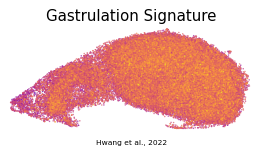

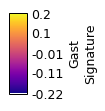

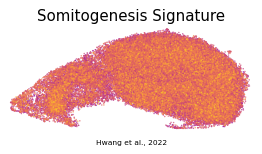

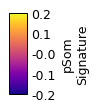

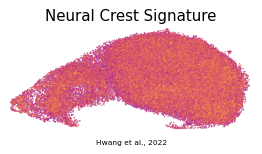

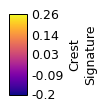

In [7]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']; xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=6, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Hwang et al., 2022', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

In [8]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (64006, 19444)
